# 11 — Vì sao KNN dự đoán sai? Truy vết hàng xóm

Phân tích ba ảnh test đã dự đoán sai bằng đúng **HSV12 + KNN k=1, uniform, Bray–Curtis**. Năm hàng xóm chỉ để quan sát; không chuyển mô hình thành k=5, không chọn lại feature/tham số và không ghi đè kết quả test.

Mục tiêu là xác minh mô hình tìm thấy ảnh train nào và khoảng cách bao nhiêu. Nhìn ảnh/histogram giúp hình thành giả thuyết về lỗi, chưa chứng minh nguyên nhân do nền, ánh sáng hay che khuất.

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import json

from sklearn.neighbors import KNeighborsClassifier
from IPython.display import display

PROJECT_ROOT = Path(r"C:\CS231")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.value_metrics import evaluate_classification

DATA_ROOT = PROJECT_ROOT / "DATA"

## 1. Chọn ba trường hợp từ dự đoán đã lưu

- `10000_002541.png`: ảnh nhìn tương đối rõ nhưng dự đoán 500.000đ.
- `10000_002183.png`: ảnh nhòe, cũng dự đoán 500.000đ.
- `500000_000096.png`: lỗi 500.000 → 20.000đ, thuộc cặp đóng góp tổng chênh lệch lớn nhất trong test.

Hai nhận xét thị giác đầu đến từ hình lỗi trong báo cáo test. Trường hợp thứ ba chọn theo cặp lỗi và thứ tự tên file, chưa gán nhãn chất lượng ảnh. Đây là các ví dụ có chủ đích, không đại diện ngẫu nhiên cho toàn test.

In [2]:
HSV_BINS = 12
CLASS_NAMES = ["10000", "20000", "50000", "100000", "200000", "500000"]

saved_predictions = pd.read_csv(
    PROJECT_ROOT / "src" / "KNN" / "results" / "hsv12_test" / "hsv12_predictions_test.csv"
)
selected_files = ["10000_002541.png", "10000_002183.png", "500000_000096.png"]
examples = saved_predictions.set_index("filename").loc[selected_files].reset_index()
display(examples)

output_dir = PROJECT_ROOT / "src" / "KNN" / "results" / "neighbor_analysis"
output_dir.mkdir(parents=True, exist_ok=True)
examples.to_csv(output_dir / "selected_test_cases.csv", index=False)

,filename,image_path,y_true,y_pred,is_correct,gap_vnd
0,10000_002541.png,DATA/test/10000/10000_002541.png,10000,500000,False,490000
1,10000_002183.png,DATA/test/10000/10000_002183.png,10000,500000,False,490000
2,500000_000096.png,DATA/test/500000/500000_000096.png,500000,20000,False,480000


## 2. Đọc từng ảnh và trích xuất feature giống notebook 10

Không nạp toàn bộ ảnh gốc vào RAM. Giữ nguyên thứ tự train theo lớp và tên file. Không resize. Vector là float32 sau khi trích xuất, giống thí nghiệm đã khóa.

In [3]:
def read_rgb(image_path):
    image_bgr = cv2.imread(str(image_path))
    return cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)


def load_image_paths_from_folder(folder):
    image_paths = []
    labels = []
    for class_name in CLASS_NAMES:
        for image_path in sorted((Path(folder) / class_name).glob("*.png")):
            image_paths.append(image_path)
            labels.append(int(class_name))
    return image_paths, np.asarray(labels, dtype=np.int64)


train_paths, y_train = load_image_paths_from_folder(DATA_ROOT / "train")
query_paths = [PROJECT_ROOT / path for path in examples["image_path"]]
print("Số ảnh train:", len(train_paths))
print("Số ảnh cần phân tích:", len(query_paths))

Số ảnh train: 12494
Số ảnh cần phân tích: 3


In [4]:
HSV_BINS = 12 

def extract_hsv_histogram(image, bins=12):

    hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist(
        [hsv_image], [0, 1, 2], None,
        [bins, bins, bins],
        [0, 180, 0, 256, 0, 256]
    )
    hist = cv2.normalize(hist, hist).flatten()
    return np.array(hist)

In [5]:
def extract_hsv_from_paths(image_paths):
    features = np.empty((len(image_paths), HSV_BINS ** 3), dtype=np.float32)
    for i, image_path in enumerate(image_paths):
        image_rgb = read_rgb(image_path)
        features[i] = extract_hsv_histogram(image_rgb, bins=HSV_BINS)
        del image_rgb
    return features


X_train_hsv = extract_hsv_from_paths(train_paths)
X_query_hsv = extract_hsv_from_paths(query_paths)
print("Train:", X_train_hsv.shape)
print("Query:", X_query_hsv.shape)

Train: (12494, 1728)
Query: (3, 1728)


## 3. Giữ k=1, tìm năm hàng xóm để xem

`predict()` dùng k=1. `kneighbors(..., n_neighbors=5)` chỉ trả danh sách để phân tích, không đổi cấu hình model. Bray–Curtis càng nhỏ thì hai vector càng gần; đây không phải độ tin cậy hay xác suất đúng. Nếu có nhiều hàng xóm cùng khoảng cách nhỏ nhất nhưng khác nhãn, cần chú ý cách xử lý hòa của thư viện; không mặc định năm hàng xóm tạo ra một quyết định mới.

In [6]:
knn = KNeighborsClassifier(
    n_neighbors=1,
    weights="uniform",
    metric="braycurtis",
    algorithm="brute"
)
knn.fit(X_train_hsv, y_train)
query_predictions = knn.predict(X_query_hsv)
distances, indices = knn.kneighbors(X_query_hsv, n_neighbors=5)

case_summary = examples.copy()
case_summary["recomputed_prediction"] = query_predictions
case_summary["matches_saved_prediction"] = query_predictions == examples["y_pred"].to_numpy()
case_summary["nearest_distance"] = distances[:, 0]
display(case_summary)
case_summary.to_csv(output_dir / "case_summary.csv", index=False)

,filename,image_path,y_true,y_pred,is_correct,gap_vnd,recomputed_prediction,matches_saved_prediction,nearest_distance
0,10000_002541.png,DATA/test/10000/10000_002541.png,10000,500000,False,490000,500000,True,0.458062
1,10000_002183.png,DATA/test/10000/10000_002183.png,10000,500000,False,490000,500000,True,0.484686
2,500000_000096.png,DATA/test/500000/500000_000096.png,500000,20000,False,480000,20000,True,0.449106


Cột `matches_saved_prediction` phải là True cho cả ba trường hợp. Nếu khác, dừng nhận xét về quyết định đã lưu và kiểm tra môi trường, dữ liệu, thứ tự train hoặc tie; không sửa kết quả test gốc cho khớp.

In [7]:
neighbor_rows = []
for case_index, (_, example) in enumerate(examples.iterrows()):
    for rank, train_index in enumerate(indices[case_index]):
        neighbor_rows.append({
            "query_filename": example["filename"],
            "query_true_vnd": int(example["y_true"]),
            "saved_prediction_vnd": int(example["y_pred"]),
            "rank": rank + 1,
            "train_image_path": train_paths[train_index].relative_to(PROJECT_ROOT).as_posix(),
            "train_label_vnd": int(y_train[train_index]),
            "distance_braycurtis": float(distances[case_index, rank]),
        })

neighbors_table = pd.DataFrame(neighbor_rows)
neighbors_table.to_csv(output_dir / "five_nearest_neighbors.csv", index=False)
display(neighbors_table)

,query_filename,query_true_vnd,saved_prediction_vnd,rank,train_image_path,train_label_vnd,distance_braycurtis
0,10000_002541.png,10000,500000,1,DATA/train/500000/500000_000742.png,500000,0.458062
1,10000_002541.png,10000,500000,2,DATA/train/500000/500000_000743.png,500000,0.470521
2,10000_002541.png,10000,500000,3,DATA/train/10000/10000_001774.png,10000,0.496353
3,10000_002541.png,10000,500000,4,DATA/train/500000/500000_000744.png,500000,0.541854
4,10000_002541.png,10000,500000,5,DATA/train/500000/500000_000752.png,500000,0.544721
5,10000_002183.png,10000,500000,1,DATA/train/500000/500000_000516.png,500000,0.484686
6,10000_002183.png,10000,500000,2,DATA/train/500000/500000_000515.png,500000,0.496010
7,10000_002183.png,10000,500000,3,DATA/train/500000/500000_000517.png,500000,0.515848
8,10000_002183.png,10000,500000,4,DATA/train/200000/200000_001470.png,200000,0.524390
9,10000_002183.png,10000,500000,5,DATA/train/10000/10000_002373.png,10000,0.564735


## 4. Đặt ảnh test cạnh năm hàng xóm

Ảnh đầu là query, năm ảnh còn lại là train theo khoảng cách tăng dần. Nhìn xem chúng giống/khác về phân bố màu, nền và bố cục ra sao. Không coi việc nhìn thấy giống nhau là bằng chứng định lượng về nguyên nhân.

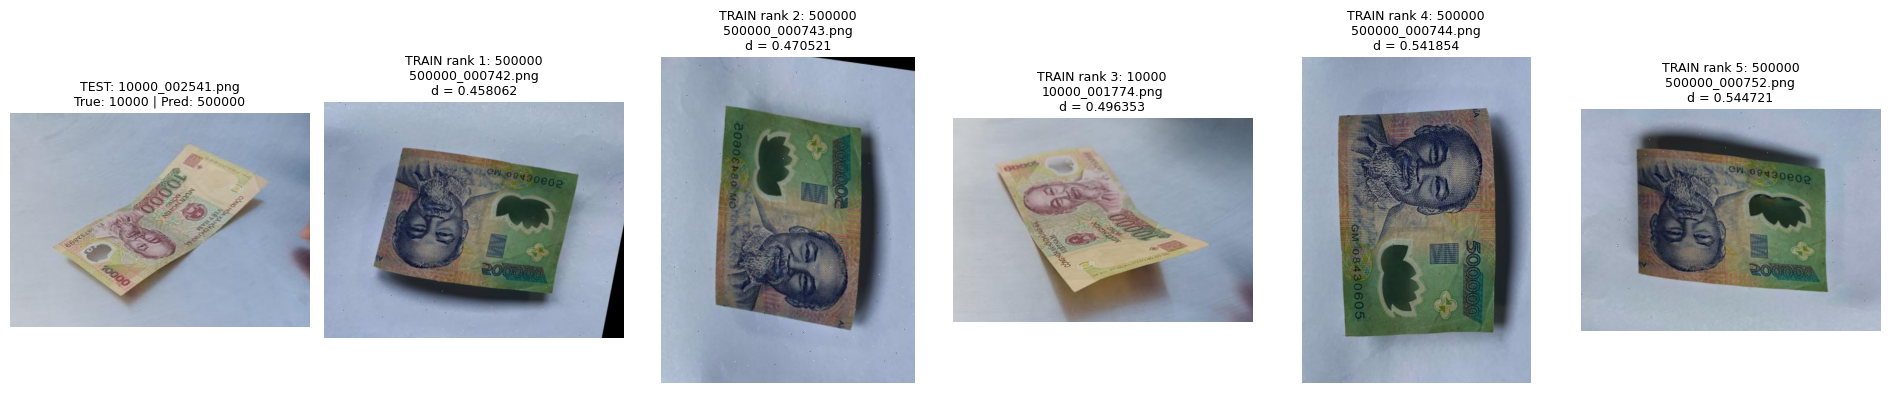

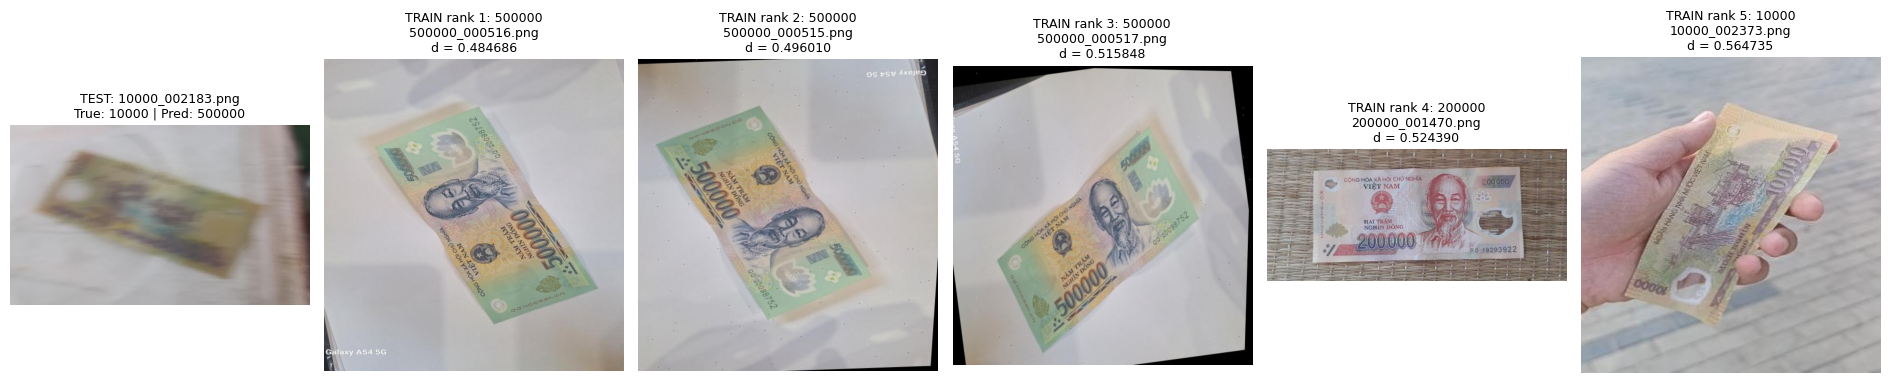

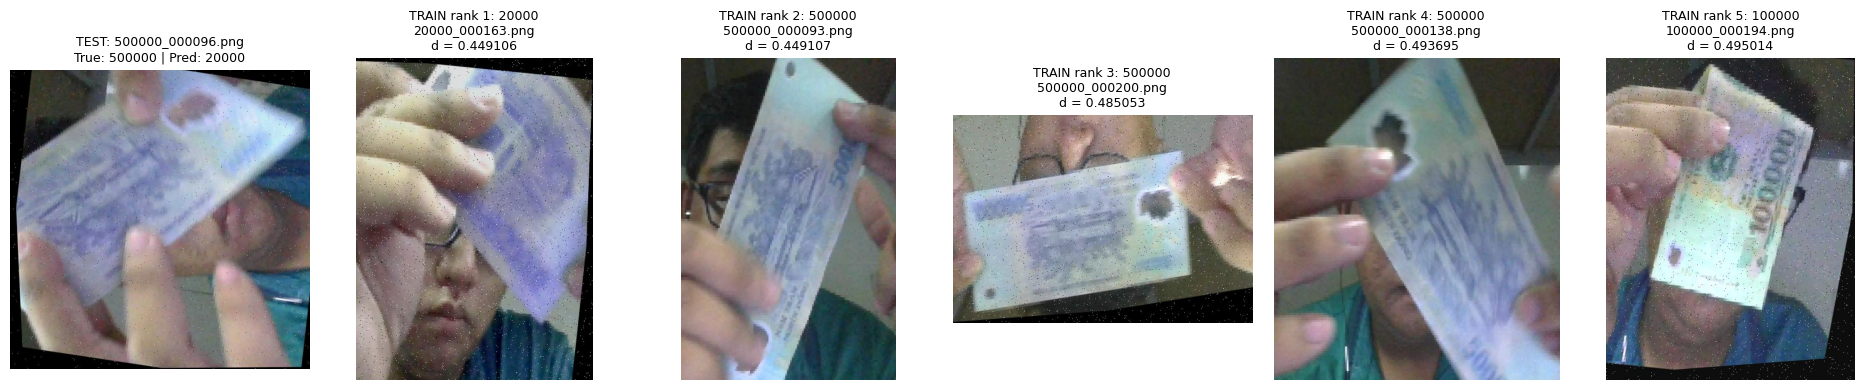

In [8]:
for case_index, (_, example) in enumerate(examples.iterrows()):
    fig, axes = plt.subplots(1, 6, figsize=(19, 4))
    axes[0].imshow(read_rgb(query_paths[case_index]))
    axes[0].set_title(f"TEST: {example['filename']}\nTrue: {example['y_true']} | Pred: {example['y_pred']}", fontsize=9)
    for rank, train_index in enumerate(indices[case_index]):
        axes[rank + 1].imshow(read_rgb(train_paths[train_index]))
        axes[rank + 1].set_title(
            f"TRAIN rank {rank + 1}: {y_train[train_index]}\n"
            f"{train_paths[train_index].name}\nd = {distances[case_index, rank]:.6f}", fontsize=9
        )
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    fig.savefig(output_dir / f"{Path(example['filename']).stem}_neighbors.png", dpi=160)
    plt.show()

## 5. Histogram query và hàng xóm đầu tiên

Đồ thị đầu hiển thị đầy đủ 1.728 bin theo thứ tự flatten; chỉ số bin không phải giá trị Hue đơn lẻ. Ba đồ thị tiếp theo cộng các trục của histogram 3D để dễ đọc. Các hình chiếu làm mất thông tin kết hợp H/S/V, nên không dùng riêng chúng để kết luận khoảng cách Bray–Curtis. Trục dọc không phải phần trăm pixel; đây là tổng các bin sau chuẩn hóa L2 cả histogram.

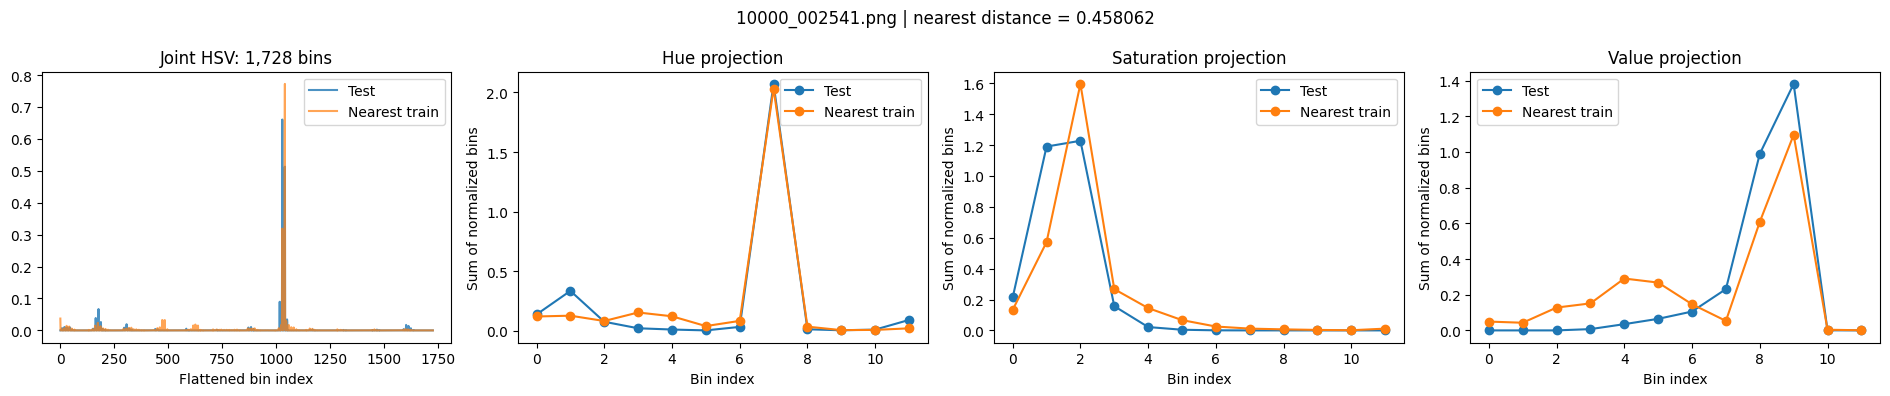

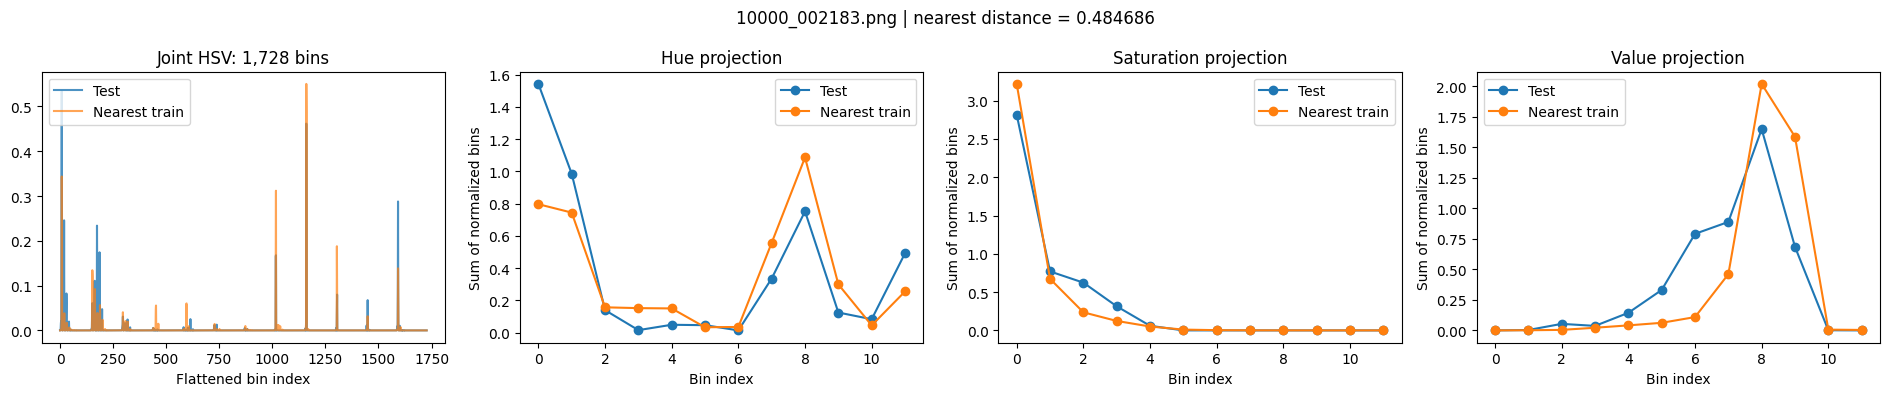

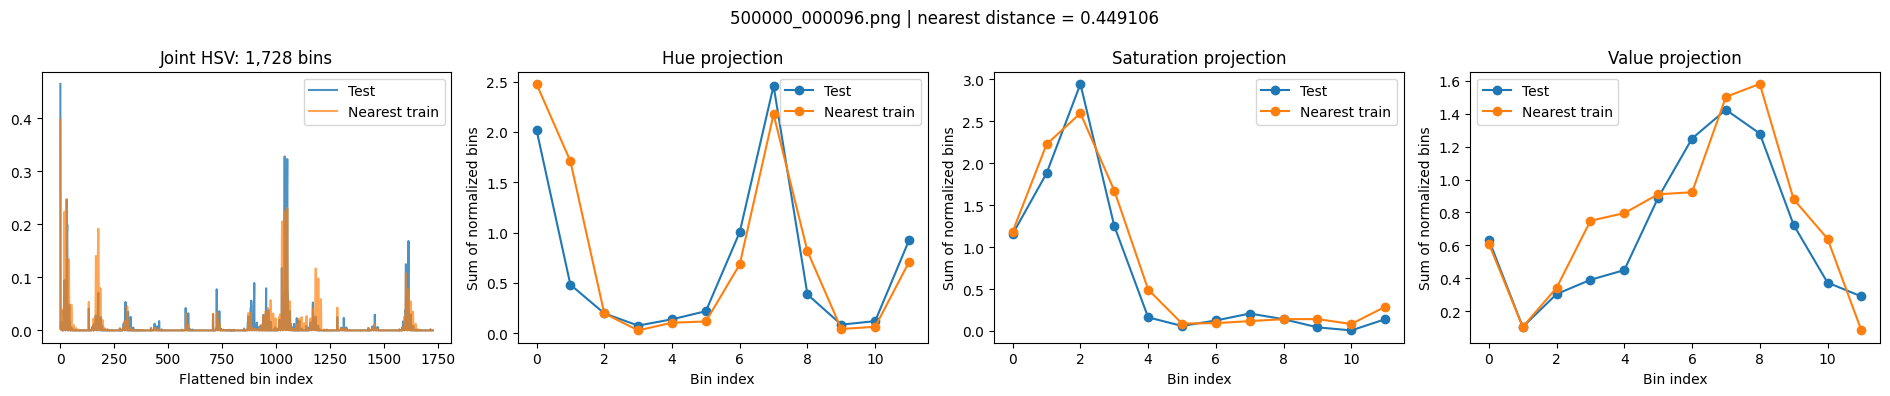

In [9]:
for case_index, (_, example) in enumerate(examples.iterrows()):
    query_feature = X_query_hsv[case_index]
    neighbor_feature = X_train_hsv[indices[case_index, 0]]
    fig, axes = plt.subplots(1, 4, figsize=(19, 4))
    axes[0].plot(query_feature, label="Test", alpha=0.8)
    axes[0].plot(neighbor_feature, label="Nearest train", alpha=0.7)
    axes[0].set_title("Joint HSV: 1,728 bins")
    axes[0].set_xlabel("Flattened bin index")
    axes[0].legend()

    query_cube = query_feature.reshape(HSV_BINS, HSV_BINS, HSV_BINS)
    neighbor_cube = neighbor_feature.reshape(HSV_BINS, HSV_BINS, HSV_BINS)
    for ax, summed_axes, title in zip(
        axes[1:], [(1, 2), (0, 2), (0, 1)], ["Hue projection", "Saturation projection", "Value projection"]
    ):
        ax.plot(query_cube.sum(axis=summed_axes), label="Test", marker="o")
        ax.plot(neighbor_cube.sum(axis=summed_axes), label="Nearest train", marker="o")
        ax.set_title(title)
        ax.set_xlabel("Bin index")
        ax.set_ylabel("Sum of normalized bins")
        ax.legend()
    fig.suptitle(f"{example['filename']} | nearest distance = {distances[case_index, 0]:.6f}")
    plt.tight_layout()
    fig.savefig(output_dir / f"{Path(example['filename']).stem}_histograms.png", dpi=160)
    plt.show()

## 6. Ghi nhận xét từ kết quả thật

Cho từng ảnh, ghi:

1. Nhãn thật, dự đoán đã lưu, dự đoán vừa tính có khớp không?
2. Hàng xóm đầu tiên là ảnh nào, nhãn gì, khoảng cách bao nhiêu? Có hòa khoảng cách giữa các nhãn khác nhau không?
3. Năm hàng xóm có mấy ảnh cùng nhãn thật? Đây chỉ là mô tả, không phải thử k=5 để cải thiện test.
4. Có thể quan sát sự tương đồng nào về màu, nền, ánh sáng? Đặc điểm nào con người dùng (chữ số, họa tiết, vị trí) không được histogram giữ lại?

Kết luận đúng mức: đã truy vết được hàng xóm và khoảng cách. Không khẳng định màu nền gây ra lỗi nếu chưa có thí nghiệm riêng. Không có ngưỡng “khoảng cách thấp là chắc chắn đúng”; cần tránh gọi khoảng cách là xác suất.

Sau khi chạy, dừng để audit và cập nhật báo cáo. Giữ nguyên kết quả test chính thức.

In [10]:
print("Đã lưu bảng và hình phân tích tại:", output_dir)
print("Dự đoán khớp kết quả test đã lưu:", case_summary["matches_saved_prediction"].tolist())

Đã lưu bảng và hình phân tích tại: C:\CS231\src\KNN\results\neighbor_analysis
Dự đoán khớp kết quả test đã lưu: [True, True, True]
